# Laboratório Multi-Doença — Café

**Objetivo:** um modelo que identifique **várias doenças na mesma folha** e mostre **onde está cada uma**.

| Etapa | Como |
|---|---|
| Dados | **BRACOL** (café arábica, UFES): 1.747 folhas com **uma coluna por doença** (bicho-mineiro, ferrugem, Phoma, cercosporiose). 372 folhas têm 2 ou mais doenças. Também há **caixas de lesões por doença**, marcadas por especialista |
| Combinações raras | **Copy-paste de lesões reais**: recortes de lesões (só de folhas de treino) colados em outras folhas, na escala correta |
| Modelo | **MobileNetV3-Large** (~4,2 M parâmetros, 7× menor que o ConvNeXt), com **uma saída independente por doença** (sigmóide), em vez de "escolher uma" |
| Onde está cada doença | **Um mapa de calor por doença** (Grad-CAM), comparado com as caixas reais das lesões |

> As fotos de café do projeto (`Base_Coffee`, `Test_Coffee`) têm uma doença por imagem, por isso o BRACOL é a base principal aqui. As fotos do projeto entram no final, como teste cruzado.

## Configuração

In [1]:
import os, sys, time, random, collections, datetime as dt
from pathlib import Path

import numpy as np
import torch, torch.nn as nn
import matplotlib.pyplot as plt
from PIL import Image, ImageDraw
from dotenv import load_dotenv
from sklearn.metrics import average_precision_score, roc_auc_score, precision_recall_fscore_support

STEPS_DIR = Path.cwd().parent                # Steps/
import multi_utils as mu

SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
print(".env carregado" if load_dotenv(STEPS_DIR / ".env") else "sem .env")

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
BRACOL_PATH = os.getenv("BRACOL_PATH", "/media/kaua-matheus/HD3201/Data/Agroscope/Coffee/BRACOL/repo")
PROJECT_TEST = os.getenv("EVAL_PATH")       # fotos de café do projeto (teste cruzado)

# Modelo final: NUNCA sobrescreve um arquivo existente
MODEL_PATH = (STEPS_DIR / os.getenv("MODEL_PATH", "Models/Saved/Expert/Coffee/coffee_multi.pth")).resolve()
if MODEL_PATH.exists():
    MODEL_PATH = MODEL_PATH.with_name(f"{MODEL_PATH.stem}_{dt.datetime.now():%Y%m%d_%H%M}{MODEL_PATH.suffix}")
for p in MODEL_PATH.parent.glob("*.pth"):
    assert p.resolve() != MODEL_PATH, "o caminho final coincide com um modelo existente"

EPOCHS, BATCH, LR = 20, 32, 5e-4
print(f"Dispositivo: {DEVICE} | modelo será salvo em: {MODEL_PATH}")

.env carregado
Dispositivo: cuda | modelo será salvo em: /home/kaua-matheus/Documents/Agroscope_IA/Steps/Models/Saved/Expert/Coffee/coffee_multi.pth


## Dados
Se a pasta do BRACOL não existir, baixe os dados do repositório dos autores (~130 MB, licença MIT):
```bash
git clone --depth 1 --filter=blob:none --sparse https://github.com/esgario/lara2018.git <BRACOL_PATH>
cd <BRACOL_PATH> && git sparse-checkout set classification/dataset segmentation/dataset
```

In [2]:
leaves, boxes, crops = mu.Load_Bracol(BRACOL_PATH)
labels = np.stack([l["labels"] for l in leaves.values()])
print(f"{len(leaves)} folhas | {sum(map(len, boxes.values()))} caixas de lesões em {len(boxes)} folhas")
print("Folhas por doença:", dict(zip(mu.DISEASES, labels.sum(0).astype(int))))
print("Folhas com 2+ doenças:", int((labels.sum(1) >= 2).sum()))

combos = collections.Counter(mu.Combo(l["labels"]) for l in leaves.values())
print("\nCombinações:")
for c, n in combos.most_common():
    print(f"  {c:30s} {n}")

1747 folhas | 1842 caixas de lesões em 1132 folhas
Folhas por doença: {'miner': np.int64(489), 'rust': np.int64(684), 'phoma': np.int64(355), 'cercospora': np.int64(322)}
Folhas com 2+ doenças: 372

Combinações:
  rust                           349
  phoma                          342
  miner                          322
  healthy                        274
  rust+cercospora                194
  miner+rust                     133
  cercospora                     88
  miner+cercospora               27
  phoma+cercospora               8
  miner+rust+cercospora          5
  rust+phoma                     3
  miner+phoma                    2


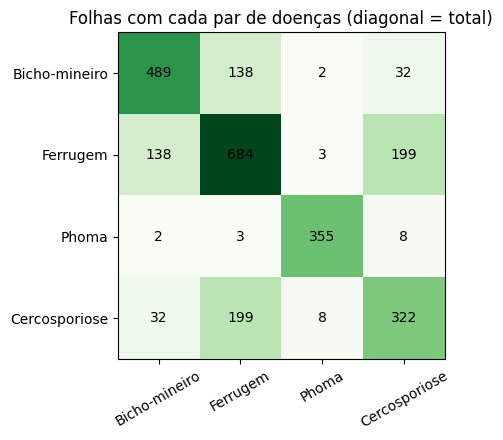

In [3]:
# Coocorrência: quantas folhas têm as duas doenças ao mesmo tempo
co = labels.T @ labels
fig, ax = plt.subplots(figsize=(5.5, 4.5))
ax.imshow(co, cmap="Greens")
names = [mu.DISEASE_PT[d] for d in mu.DISEASES]
ax.set_xticks(range(4), names, rotation=30); ax.set_yticks(range(4), names)
for i in range(4):
    for j in range(4):
        ax.text(j, i, int(co[i, j]), ha="center", va="center")
ax.set_title("Folhas com cada par de doenças (diagonal = total)")
plt.tight_layout(); plt.show()

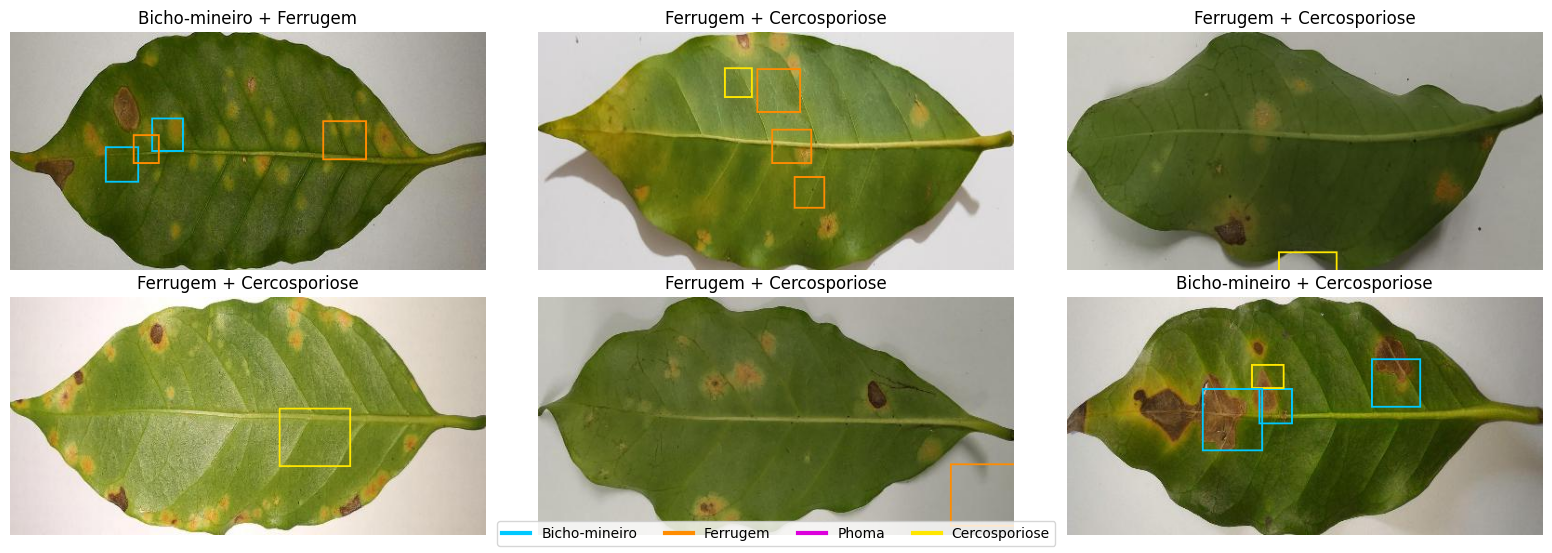

In [4]:
# Exemplos reais de folhas com mais de uma doença, com as caixas das lesões
def draw_boxes(img, bxs, width=2):
    img = img.copy(); d = ImageDraw.Draw(img)
    for dis, x0, y0, x1, y1 in bxs:
        d.rectangle([x0, y0, x1, y1], outline=mu.DISEASE_COLOR[dis], width=width)
    return img

multi_boxed = [i for i, l in leaves.items() if l["labels"].sum() >= 2 and len({b[0] for b in boxes.get(i, [])}) >= 2]
fig, axes = plt.subplots(2, 3, figsize=(16, 5.5))
for ax, lid in zip(axes.flat, random.Random(1).sample(multi_boxed, 6)):
    img = Image.open(leaves[lid]["path"]).convert("RGB").resize((mu.IMG_W, mu.IMG_H))
    ax.imshow(draw_boxes(img, boxes[lid])); ax.axis("off")
    ax.set_title(" + ".join(mu.DISEASE_PT[d] for d in mu.DISEASES if leaves[lid]["labels"][mu.DISEASES.index(d)]))
handles = [plt.Line2D([], [], color=np.array(mu.DISEASE_COLOR[d]) / 255, lw=3, label=mu.DISEASE_PT[d]) for d in mu.DISEASES]
fig.legend(handles=handles, loc="lower center", ncol=4); plt.tight_layout(); plt.show()

## Divisão treino / validação / teste
Estratificada pela combinação de doenças. O **teste fica com 25%** para ter folhas multi-doença suficientes (inclusive com caixas para todas as doenças, usadas na avaliação da localização).

In [5]:
split = mu.Split(leaves, boxes)
for name, ids in split.items():
    lab = np.stack([leaves[i]["labels"] for i in ids])
    print(f"{name:5s}: {len(ids):4d} folhas | 2+ doenças: {int((lab.sum(1) >= 2).sum()):3d} | por doença: {dict(zip(mu.DISEASES, lab.sum(0).astype(int)))}")
assert not (set(split["train"]) & set(split["test"])) and not (set(split["val"]) & set(split["test"]))

train: 1052 folhas | 2+ doenças: 226 | por doença: {'miner': np.int64(294), 'rust': np.int64(413), 'phoma': np.int64(215), 'cercospora': np.int64(194)}
val  :  260 folhas | 2+ doenças:  55 | por doença: {'miner': np.int64(73), 'rust': np.int64(102), 'phoma': np.int64(52), 'cercospora': np.int64(48)}
test :  435 folhas | 2+ doenças:  91 | por doença: {'miner': np.int64(122), 'rust': np.int64(169), 'phoma': np.int64(88), 'cercospora': np.int64(80)}


## Copy-paste de lesões reais
Para ensinar o modelo a reconhecer **qualquer combinação**, incluindo as raras (ex.: ferrugem + Phoma tem só 3 folhas reais), lesões reais são coladas em outras folhas durante o treino:
- só recortes de **folhas do treino** (sem vazar o teste);
- na **escala original** da folha;
- dentro da folha, com **borda suave** e **brilho ajustado**;
- sem os pixels de fundo do recorte;
- favorecendo as doenças com menos exemplos.

A folha passa a ter o rótulo da doença colada além dos que já tinha.

Lesões disponíveis para colar (só de folhas de treino): {'miner': 323, 'rust': 387, 'phoma': 263, 'cercospora': 132}


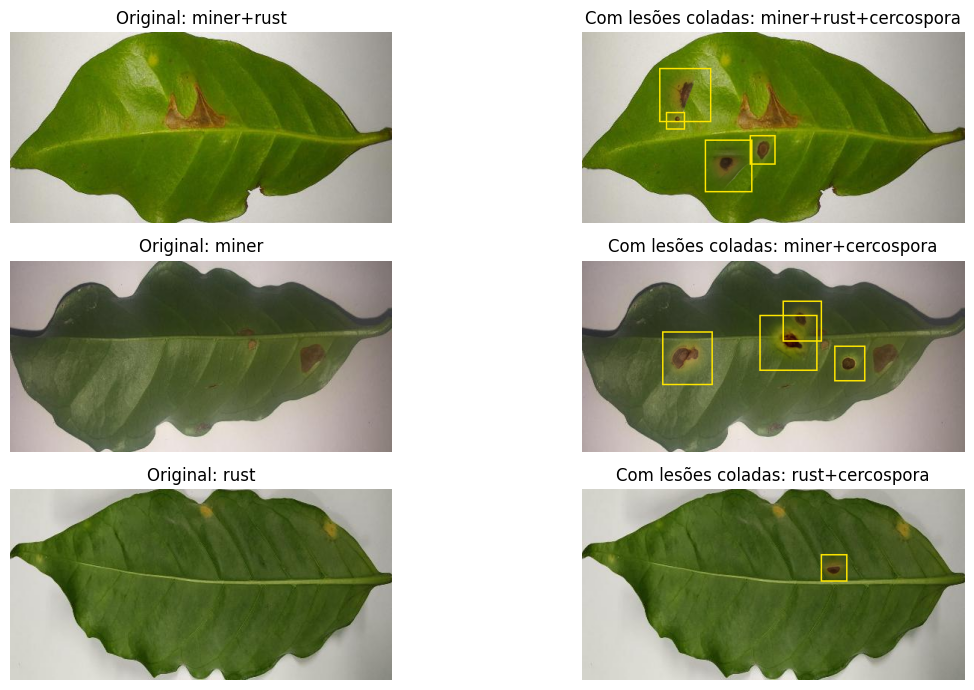

In [6]:
bank = mu.Lesion_Bank(crops, split["train"])
print("Lesões disponíveis para colar (só de folhas de treino):", bank.counts())

rng = random.Random(3)
fig, axes = plt.subplots(3, 2, figsize=(13, 7))
for row, lid in zip(axes, rng.sample(split["train"], 3)):
    img = Image.open(leaves[lid]["path"]).convert("RGB").resize((mu.IMG_W, mu.IMG_H))
    out, lab, pasted = mu.Paste_Lesions(img, leaves[lid]["labels"], bank, rng)
    row[0].imshow(img); row[0].set_title("Original: " + mu.Combo(leaves[lid]["labels"])); row[0].axis("off")
    row[1].imshow(draw_boxes(out, pasted)); row[1].set_title("Com lesões coladas: " + mu.Combo(lab)); row[1].axis("off")
plt.tight_layout(); plt.show()

## Modelo e treino
MobileNetV3-Large pré-treinado no ImageNet, com 4 saídas sigmóides (uma por doença). Folha saudável = nenhuma doença acima do limiar.

Treinamos **duas versões**, para medir se o copy-paste ajuda:
- **A**: só as folhas reais;
- **B**: folhas reais + copy-paste (25% das amostras de treino recebem lesões coladas; a melhor intensidade no experimento com 3 sementes, abaixo).

A melhor época de cada uma é escolhida pela **precisão média (mAP)** na validação.

In [7]:
val_loader = torch.utils.data.DataLoader(mu.Leaf_Dataset(split["val"], leaves, mu.Eval_Transform()), batch_size=64, num_workers=6)
test_loader = torch.utils.data.DataLoader(mu.Leaf_Dataset(split["test"], leaves, mu.Eval_Transform()), batch_size=64, num_workers=6)

train_labels = np.stack([leaves[i]["labels"] for i in split["train"]])
pos_weight = torch.tensor(np.clip((len(train_labels) - train_labels.sum(0)) / train_labels.sum(0), 1, 4), dtype=torch.float32)


def train_model(p_paste, name):
    torch.manual_seed(SEED); random.seed(SEED); np.random.seed(SEED)
    ds = mu.Leaf_Dataset(split["train"], leaves, mu.Train_Transform(), bank=bank, p_paste=p_paste)
    loader = torch.utils.data.DataLoader(ds, batch_size=BATCH, shuffle=True, num_workers=8, persistent_workers=True,
                                         drop_last=True, generator=torch.Generator().manual_seed(SEED))
    net = mu.Build_Multi_Model().to(DEVICE)
    opt = torch.optim.AdamW(net.parameters(), lr=LR, weight_decay=1e-4)
    steps = EPOCHS * len(loader)
    sched = torch.optim.lr_scheduler.OneCycleLR(opt, max_lr=LR, total_steps=steps, pct_start=0.1)
    crit = nn.BCEWithLogitsLoss(pos_weight=pos_weight.to(DEVICE))
    hist, best, best_state = [], -1, None
    t0 = time.time()
    for ep in range(EPOCHS):
        net.train(); total = 0
        for x, y in loader:
            x, y = x.to(DEVICE), y.to(DEVICE)
            with torch.autocast(DEVICE.type, dtype=torch.bfloat16, enabled=DEVICE.type == "cuda"):
                loss = crit(net(x), y)
            opt.zero_grad(); loss.backward(); opt.step(); sched.step()
            total += loss.item() * len(x)
        P, Y = mu.Predict_Probs(net, val_loader, DEVICE)
        m_ap = average_precision_score(Y, P, average="macro")
        hist.append((total / len(ds), m_ap))
        if m_ap > best:
            best, best_state = m_ap, {k: v.detach().clone() for k, v in net.state_dict().items()}
        print(f"[{name}] época {ep + 1:2d} | loss {total / len(ds):.4f} | mAP val {m_ap:.4f} | {time.time() - t0:.0f}s")
    net.load_state_dict(best_state)
    return net, hist, best


results = {}
for name, p in [("A_sem_copy_paste", 0.0), ("B_com_copy_paste", 0.25)]:
    results[name] = train_model(p, name)

[A_sem_copy_paste] época  1 | loss 0.8907 | mAP val 0.7022 | 9s
[A_sem_copy_paste] época  2 | loss 0.4506 | mAP val 0.8494 | 16s
[A_sem_copy_paste] época  3 | loss 0.2844 | mAP val 0.9141 | 23s
[A_sem_copy_paste] época  4 | loss 0.2157 | mAP val 0.8882 | 31s
[A_sem_copy_paste] época  5 | loss 0.1972 | mAP val 0.9183 | 38s
[A_sem_copy_paste] época  6 | loss 0.1938 | mAP val 0.9284 | 45s
[A_sem_copy_paste] época  7 | loss 0.1712 | mAP val 0.9237 | 52s
[A_sem_copy_paste] época  8 | loss 0.1344 | mAP val 0.9298 | 60s
[A_sem_copy_paste] época  9 | loss 0.1307 | mAP val 0.9145 | 67s
[A_sem_copy_paste] época 10 | loss 0.0928 | mAP val 0.9275 | 74s
[A_sem_copy_paste] época 11 | loss 0.0790 | mAP val 0.9183 | 81s
[A_sem_copy_paste] época 12 | loss 0.0573 | mAP val 0.9238 | 89s
[A_sem_copy_paste] época 13 | loss 0.0531 | mAP val 0.9268 | 96s
[A_sem_copy_paste] época 14 | loss 0.0515 | mAP val 0.9256 | 103s
[A_sem_copy_paste] época 15 | loss 0.0417 | mAP val 0.9330 | 110s
[A_sem_copy_paste] época

### O copy-paste ajuda? (3 sementes)
Uma única comparação A × B pode ser sorte de inicialização. O script `exp_copy_paste.py` repete o treino com **3 sementes** e três intensidades de colagem (0%, 25% e 50% das amostras).

In [8]:
import json
exp_file = Path("exp_copy_paste_results.json")
if exp_file.exists():
    exp = json.load(open(exp_file))
    print(f"{'colagem':>8s} | {'mAP teste':>13s} | {'acerto exato':>13s} | {'2+ doenças: todas':>18s} | AP por doença ({', '.join(mu.DISEASES)})")
    for p in sorted({r["p_paste"] for r in exp}):
        rs = [r for r in exp if r["p_paste"] == p]
        f = lambda k: f"{np.mean([r[k] for r in rs]) * 100:5.1f} ± {np.std([r[k] for r in rs]) * 100:3.1f}"
        ap = np.mean([r["test_AP"] for r in rs], 0)
        print(f"{p * 100:7.0f}% | {f('test_mAP'):>13s} | {f('exact'):>13s} | {f('multi_all_found'):>18s} | " + " ".join(f"{a:.3f}" for a in ap))
else:
    print("Rode `python exp_copy_paste.py` para gerar a comparação com 3 sementes (~25 min).")

 colagem |     mAP teste |  acerto exato |  2+ doenças: todas | AP por doença (miner, rust, phoma, cercospora)
      0% |    92.1 ± 1.1 |    77.8 ± 1.5 |         64.1 ± 3.6 | 0.949 0.993 0.984 0.759
     25% |    93.6 ± 0.1 |    80.8 ± 1.3 |         60.1 ± 8.3 | 0.950 0.996 0.994 0.803
     50% |    93.0 ± 0.6 |    79.4 ± 1.1 |         61.5 ± 4.1 | 0.948 0.993 0.994 0.783


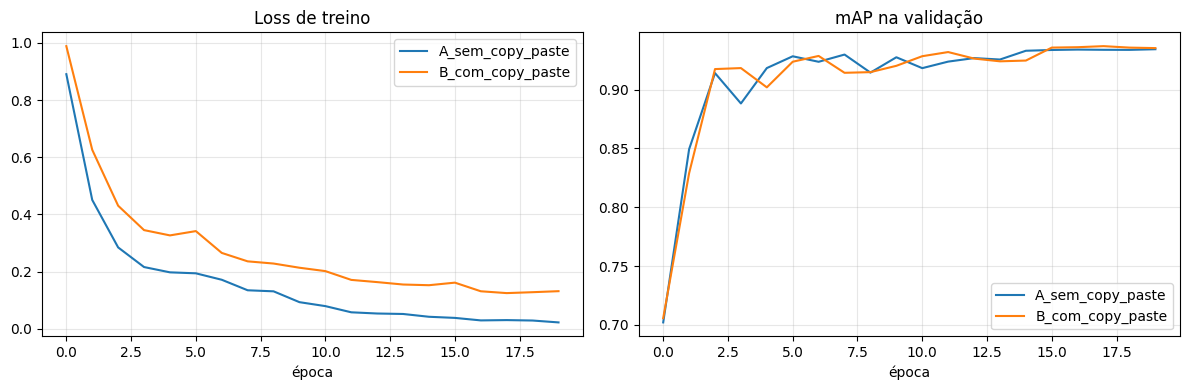

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for name, (_, hist, _) in results.items():
    axes[0].plot([h[0] for h in hist], label=name); axes[1].plot([h[1] for h in hist], label=name)
axes[0].set_title("Loss de treino"); axes[1].set_title("mAP na validação")
for a in axes: a.set_xlabel("época"); a.legend(); a.grid(alpha=.3)
plt.tight_layout(); plt.show()

## Avaliação no teste
Um limiar por doença é escolhido na **validação** (o que maximiza o F1) e aplicado no teste.

Métricas:
- **AP** (precisão média) e **AUC**: qualidade da saída de cada doença, independente do limiar;
- **Precisão / Recall / F1** de cada doença, com o limiar escolhido;
- **Acerto exato**: todas as doenças da folha corretas, sem nenhuma a mais nem a menos;
- **Folhas com 2+ doenças**: em quantas o modelo encontrou **todas**.

In [10]:
def evaluate(net, name):
    Pv, Yv = mu.Predict_Probs(net, val_loader, DEVICE)
    thr = mu.Best_Thresholds(Pv, Yv)
    P, Y = mu.Predict_Probs(net, test_loader, DEVICE)
    pred = (P >= thr).astype(int)
    prec, rec, f1, _ = precision_recall_fscore_support(Y, pred, zero_division=0)
    multi = Y.sum(1) >= 2
    row = {
        "mAP": average_precision_score(Y, P, average="macro"),
        "AUC": roc_auc_score(Y, P, average="macro"),
        "F1 médio": f1.mean(),
        "acerto exato": (pred == Y).all(1).mean(),
        "saudáveis corretas": (pred[Y.sum(1) == 0].sum(1) == 0).mean(),
        "2+ doenças: todas encontradas": ((pred[multi] >= Y[multi]).all(1)).mean(),
        "2+ doenças: acerto exato": (pred[multi] == Y[multi]).all(1).mean(),
    }
    per = {d: dict(AP=average_precision_score(Y[:, k], P[:, k]), precisão=prec[k], recall=rec[k], F1=f1[k], limiar=thr[k])
           for k, d in enumerate(mu.DISEASES)}
    return row, per, thr, (P, Y, pred)


evals = {name: evaluate(net, name) for name, (net, _, _) in results.items()}
print(f"{'':32s}" + "".join(f"{n:>20s}" for n in evals))
for key in next(iter(evals.values()))[0]:
    print(f"{key:32s}" + "".join(f"{e[0][key] * 100:19.1f}%" for e in evals.values()))
print(f"\n(teste: {len(split['test'])} folhas, {int((evals['A_sem_copy_paste'][3][1].sum(1) >= 2).sum())} com 2+ doenças)")

                                    A_sem_copy_paste    B_com_copy_paste
mAP                                            92.9%               93.7%
AUC                                            97.0%               97.5%
F1 médio                                       86.1%               87.6%
acerto exato                                   77.9%               81.8%
saudáveis corretas                             98.5%               98.5%
2+ doenças: todas encontradas                  68.1%               60.4%
2+ doenças: acerto exato                       58.2%               54.9%

(teste: 435 folhas, 91 com 2+ doenças)


In [11]:
for name, (_, per, _, _) in evals.items():
    print(f"\n== {name}")
    print(f"{'doença':16s}{'AP':>8s}{'precisão':>10s}{'recall':>8s}{'F1':>8s}{'limiar':>8s}")
    for d, m in per.items():
        print(f"{mu.DISEASE_PT[d]:16s}{m['AP']:8.3f}{m['precisão']:10.3f}{m['recall']:8.3f}{m['F1']:8.3f}{m['limiar']:8.2f}")


== A_sem_copy_paste
doença                AP  precisão  recall      F1  limiar
Bicho-mineiro      0.961     0.888   0.910   0.899    0.81
Ferrugem           0.993     0.923   0.988   0.954    0.10
Phoma              0.993     0.955   0.966   0.960    0.55
Cercosporiose      0.770     0.558   0.725   0.630    0.26

== B_com_copy_paste
doença                AP  precisão  recall      F1  limiar
Bicho-mineiro      0.945     0.856   0.926   0.890    0.49
Ferrugem           0.994     0.954   0.976   0.965    0.51
Phoma              0.991     0.935   0.989   0.961    0.40
Cercosporiose      0.816     0.732   0.650   0.689    0.87


In [12]:
# Escolha do modelo final pela VALIDAÇÃO (nunca pelo teste), com um critério que reflete o objetivo:
# qualidade geral (mAP) + encontrar TODAS as doenças nas folhas com 2 ou mais doenças.
def val_score(net):
    Pv, Yv = mu.Predict_Probs(net, val_loader, DEVICE)
    thr = mu.Best_Thresholds(Pv, Yv)
    multi = Yv.sum(1) >= 2
    all_found = ((Pv[multi] >= thr) >= Yv[multi]).all(1).mean()
    return average_precision_score(Yv, Pv, average="macro"), all_found

scores = {n: val_score(results[n][0]) for n in results}
for n, (m, a) in scores.items():
    print(f"{n}: mAP val {m * 100:.1f}% | 2+ doenças, todas encontradas (val) {a * 100:.1f}% | critério {(m + a) / 2 * 100:.1f}")
best_name = max(scores, key=lambda n: sum(scores[n]))
net, _, _ = results[best_name]
row, per, THR, (P, Y, PRED) = evals[best_name]
print(f"\nModelo escolhido: {best_name}")

A_sem_copy_paste: mAP val 93.4% | 2+ doenças, todas encontradas (val) 69.1% | critério 81.3
B_com_copy_paste: mAP val 93.7% | 2+ doenças, todas encontradas (val) 54.5% | critério 74.1

Modelo escolhido: A_sem_copy_paste


### Ajuste de sensibilidade (limiares)
Os limiares de cada doença foram escolhidos para o melhor F1 de cada uma separadamente, o que favorece a precisão. Para **não deixar passar a segunda doença** de uma folha, dá para baixar todos os limiares por um fator.

A tabela mostra o efeito na **validação** (onde o ajuste deve ser escolhido) e no **teste**:
- **todas encontradas**: folhas com 2+ doenças em que todas foram achadas;
- **doença a mais**: folhas que recebem alguma doença que não têm (alarme falso);
- **saudáveis corretas**: folhas saudáveis sem nenhuma doença apontada.

In [13]:
Pv, Yv = mu.Predict_Probs(net, val_loader, DEVICE)
def operating_point(Pr, Yr, thr):
    pred = (Pr >= thr).astype(int); multi = Yr.sum(1) >= 2; healthy = Yr.sum(1) == 0
    return ((pred[multi] >= Yr[multi]).all(1).mean(), ((pred - Yr) > 0).any(1).mean(), (pred[healthy].sum(1) == 0).mean(), (pred == Yr).all(1).mean())
print(f"{'fator':>6s} | {'VALIDAÇÃO: todas enc.':>22s} {'doença a mais':>14s} {'saudáveis ok':>13s} | {'TESTE: todas enc.':>18s} {'doença a mais':>14s} {'saudáveis ok':>13s} {'acerto exato':>13s}")
for f in (1.0, 0.8, 0.6, 0.4, 0.25):
    v = operating_point(Pv, Yv, THR * f); t = operating_point(P, Y, THR * f)
    print(f"{f:6.2f} | {v[0] * 100:21.1f}% {v[1] * 100:13.1f}% {v[2] * 100:12.1f}% | {t[0] * 100:17.1f}% {t[1] * 100:13.1f}% {t[2] * 100:12.1f}% {t[3] * 100:12.1f}%")

 fator |  VALIDAÇÃO: todas enc.  doença a mais  saudáveis ok |  TESTE: todas enc.  doença a mais  saudáveis ok  acerto exato
  1.00 |                  69.1%           9.6%        100.0% |              68.1%          17.5%         98.5%         77.9%
  0.80 |                  69.1%          11.5%        100.0% |              71.4%          18.9%         98.5%         77.5%
  0.60 |                  72.7%          14.2%        100.0% |              72.5%          20.9%         98.5%         75.6%
  0.40 |                  74.5%          17.3%        100.0% |              72.5%          22.8%         97.1%         74.0%
  0.25 |                  81.8%          19.6%        100.0% |              76.9%          26.0%         97.1%         71.7%


## Onde está cada doença
Para cada doença detectada, o **Grad-CAM daquela saída** mostra quais regiões da folha a fizeram "acender". Cada doença tem uma cor; no mapa combinado, cada região recebe a cor da doença mais forte ali.

### Medida objetiva (pointing game)
Para cada folha de teste e cada doença que tem caixas marcadas pelo especialista, verificamos se o **ponto mais quente** do mapa daquela doença cai **dentro de uma lesão daquela doença**. A comparação é com o acerto "no chute" (um ponto aleatório da folha), que é a fração da folha coberta por essas lesões.

> **Limitações das caixas reais:**
> - Elas não marcam todas as lesões; na ferrugem, por exemplo, só algumas das muitas manchas. Por isso a medida é **conservadora**: um ponto quente sobre uma lesão real não marcada conta como erro.
> - 8,5% das caixas caem fora da folha (coordenadas deslocadas); essas são descartadas.
>
> Por isso há também um segundo teste, com **posição exata**: lesões de folhas de teste coladas em folhas saudáveis de teste.

In [14]:
cam = mu.Multi_GradCAM(net)
tf = mu.Eval_Transform()
loc = collections.defaultdict(list)   # (doença, simples/multi) -> [(acertou, chance_no_chute)]
discr = []                            # folhas multi-doença: o mapa da doença A aponta para A (e não para B)?

for lid in split["test"]:
    bx = boxes.get(lid, [])
    if not bx:
        continue
    img = Image.open(leaves[lid]["path"]).convert("RGB").resize((mu.IMG_W, mu.IMG_H))
    leaf_mask = mu.Leaf_Mask(img)
    bx = mu.Valid_Boxes(bx, leaf_mask)   # 8,5% das caixas do BRACOL caem fora da folha (coordenadas deslocadas)
    if not bx:
        continue
    present = [k for k in range(4) if leaves[lid]["labels"][k]]
    _, cams = cam(tf(img).unsqueeze(0).to(DEVICE), present)
    kind = "multi" if len(present) >= 2 else "simples"
    boxed = {b[0] for b in bx}
    for k in present:
        d = mu.DISEASES[k]
        own = [b for b in bx if b[0] == d]
        if not own:
            continue
        loc[(d, kind)].append((mu.Pointing_Hit(cams[k], own, leaf_mask), mu.Box_Area_Fraction(own, leaf_mask)))
        others = [b for b in bx if b[0] != d]
        if kind == "multi" and others and len(boxed) >= 2:
            discr.append((mu.Pointing_Hit(cams[k], own, leaf_mask), mu.Pointing_Hit(cams[k], others, leaf_mask)))

print(f"{'doença':16s}{'tipo':>9s}{'n':>5s}{'acerto':>9s}{'no chute':>10s}")
for (d, kind), v in sorted(loc.items()):
    a = np.array(v)
    print(f"{mu.DISEASE_PT[d]:16s}{kind:>9s}{len(a):5d}{a[:, 0].mean() * 100:8.1f}%{a[:, 1].mean() * 100:9.1f}%")
allv = np.array([x for v in loc.values() for x in v])
print(f"{'TOTAL':16s}{'':>9s}{len(allv):5d}{allv[:, 0].mean() * 100:8.1f}%{allv[:, 1].mean() * 100:9.1f}%")
d_arr = np.array(discr)
print(f"\nFolhas multi-doença ({len(d_arr)} pares doença-folha): o mapa da doença aponta para lesões DELA em "
      f"{d_arr[:, 0].mean() * 100:.1f}% e para lesões de OUTRA doença em {d_arr[:, 1].mean() * 100:.1f}%")

doença               tipo    n   acerto  no chute
Cercosporiose       multi   19    36.8%      4.4%
Cercosporiose     simples   14    35.7%      5.2%
Bicho-mineiro       multi   19    52.6%      5.1%
Bicho-mineiro     simples   71    80.3%      8.4%
Phoma             simples   70    70.0%     10.5%
Ferrugem            multi   24    25.0%      7.0%
Ferrugem          simples   56    26.8%      8.6%
TOTAL                      273    54.6%      8.2%

Folhas multi-doença (20 pares doença-folha): o mapa da doença aponta para lesões DELA em 50.0% e para lesões de OUTRA doença em 0.0%


In [15]:
# Localização com posição EXATA: lesões de folhas de TESTE (nunca vistas) coladas em folhas SAUDÁVEIS de teste.
# Como a folha era saudável, toda lesão está marcada e a doença de cada uma é conhecida.
rng = random.Random(5)
test_bank = mu.Lesion_Bank(crops, split["test"])
healthy_test = [i for i in split["test"] if leaves[i]["labels"].sum() == 0]
exact = collections.defaultdict(list); exact_discr = []; exact_found = []
for lid in healthy_test:
    for _ in range(3):
        img = Image.open(leaves[lid]["path"]).convert("RGB").resize((mu.IMG_W, mu.IMG_H))
        lab, all_boxes = leaves[lid]["labels"], []
        for d in rng.sample([d for d in mu.DISEASES if test_bank.items[d]], 2):
            img, lab, b = mu.Paste_Lesions(img, lab, test_bank, rng, disease=d, n_range=(1, 3)); all_boxes += b
        present = [k for k in range(4) if lab[k]]
        if len(present) < 2:
            continue
        probs, cams = cam(tf(img).unsqueeze(0).to(DEVICE), present)
        exact_found.append(all(probs[k] >= THR[k] for k in present))
        leaf_mask = mu.Leaf_Mask(img)
        for k in present:
            d = mu.DISEASES[k]
            own = [b for b in all_boxes if b[0] == d]; other = [b for b in all_boxes if b[0] != d]
            exact[d].append((mu.Pointing_Hit(cams[k], own, leaf_mask), mu.Box_Area_Fraction(own, leaf_mask)))
            exact_discr.append((mu.Pointing_Hit(cams[k], own, leaf_mask), mu.Pointing_Hit(cams[k], other, leaf_mask)))

print(f"{len(exact_found)} folhas com 2 doenças coladas | as 2 doenças detectadas em {np.mean(exact_found) * 100:.1f}%")
print(f"{'doença':16s}{'n':>5s}{'acerto':>9s}{'no chute':>10s}")
for d, v in exact.items():
    a = np.array(v); print(f"{mu.DISEASE_PT[d]:16s}{len(a):5d}{a[:, 0].mean() * 100:8.1f}%{a[:, 1].mean() * 100:9.1f}%")
e = np.array(exact_discr)
print(f"O mapa de cada doença aponta para lesões DELA em {e[:, 0].mean() * 100:.1f}% e para lesões da OUTRA doença em {e[:, 1].mean() * 100:.1f}%")

204 folhas com 2 doenças coladas | as 2 doenças detectadas em 30.9%
doença              n   acerto  no chute
Phoma              96    25.0%     13.2%
Cercosporiose     101    87.1%     11.1%
Bicho-mineiro     108    76.9%     10.5%
Ferrugem          103    98.1%     11.2%
O mapa de cada doença aponta para lesões DELA em 72.5% e para lesões da OUTRA doença em 17.4%


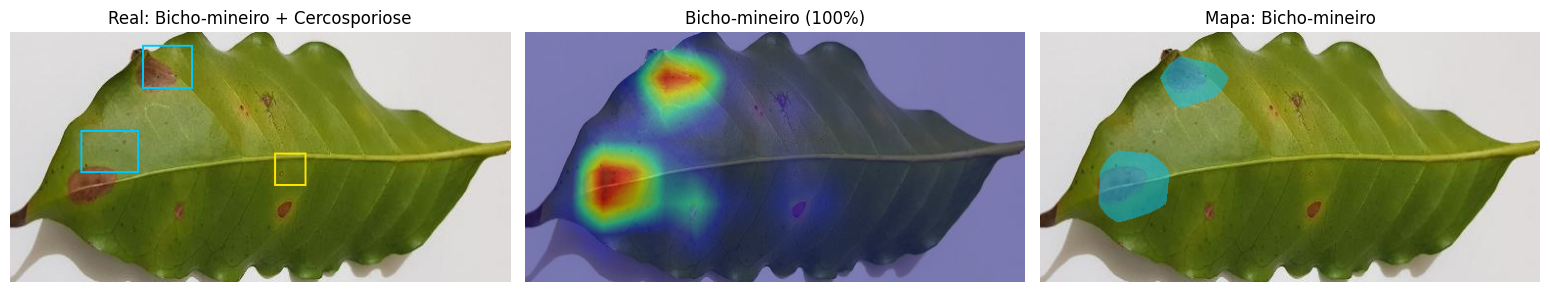

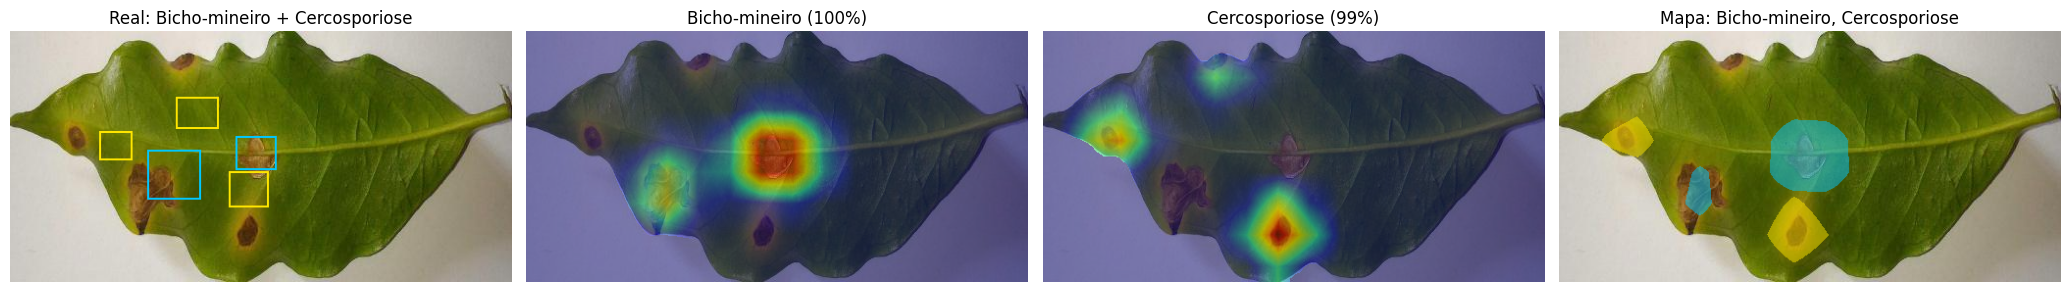

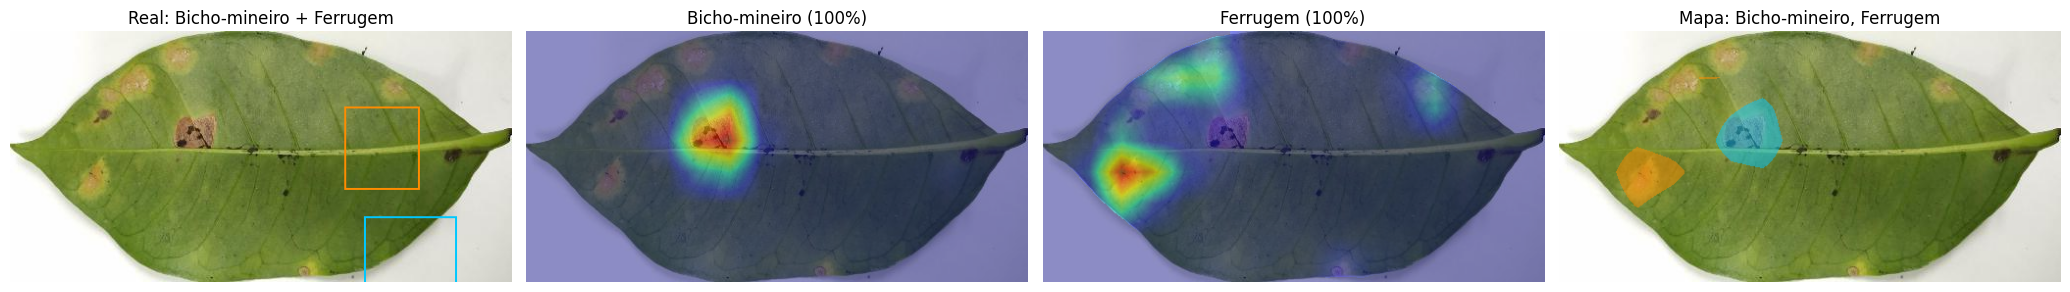

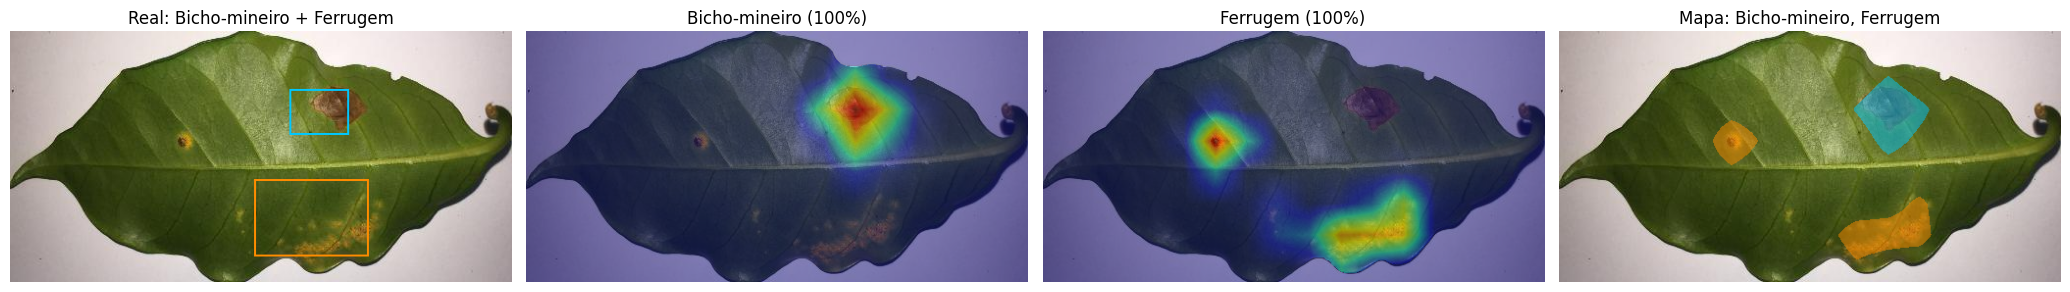

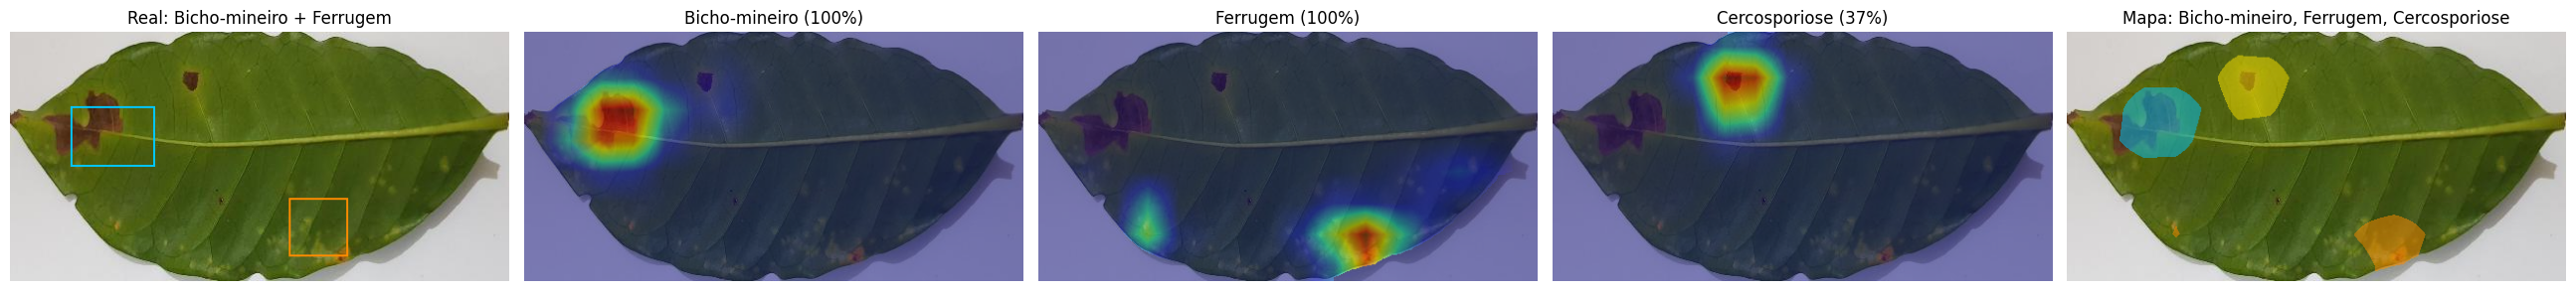

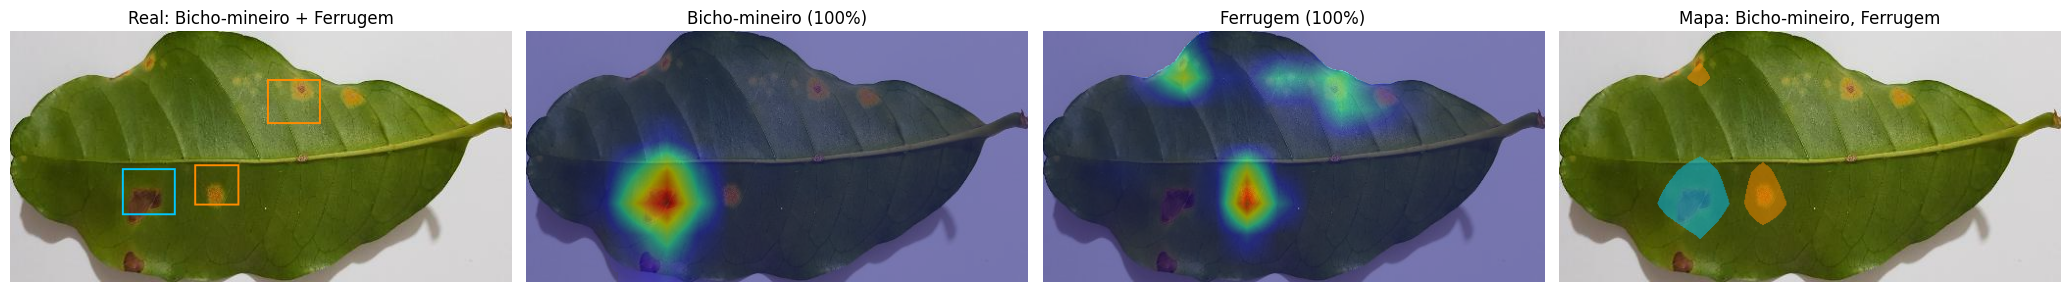

In [16]:
def show_leaf(lid=None, img=None, gt_boxes=(), title=""):
    img = img if img is not None else Image.open(leaves[lid]["path"]).convert("RGB").resize((mu.IMG_W, mu.IMG_H))
    probs, cams = cam(tf(img).unsqueeze(0).to(DEVICE))
    found = [k for k in range(4) if probs[k] >= THR[k]]
    leaf_mask = mu.Leaf_Mask(img)
    fig, axes = plt.subplots(1, 2 + max(1, len(found)), figsize=(5.2 * (2 + max(1, len(found))), 3.2))
    axes[0].imshow(draw_boxes(img, gt_boxes)); axes[0].set_title(title or "Original (caixas = especialista)"); axes[0].axis("off")
    for ax, k in zip(axes[1:-1], found):
        ax.imshow(img); ax.imshow(np.where(leaf_mask, cams[k], 0), cmap="jet", alpha=0.45)
        ax.set_title(f"{mu.DISEASE_PT[mu.DISEASES[k]]} ({probs[k] * 100:.0f}%)"); ax.axis("off")
    if not found:
        axes[1].imshow(img); axes[1].set_title("Nenhuma doença detectada"); axes[1].axis("off")
    axes[-1].imshow(mu.Disease_Map(img, cams, found, leaf_mask)); axes[-1].axis("off")
    axes[-1].set_title("Mapa: " + (", ".join(mu.DISEASE_PT[mu.DISEASES[k]] for k in found) or "saudável"))
    plt.tight_layout(); plt.show()


test_multi = [i for i in split["test"] if leaves[i]["labels"].sum() >= 2 and len({b[0] for b in boxes.get(i, [])}) >= 2]
for lid in test_multi[:6]:
    show_leaf(lid, gt_boxes=boxes[lid], title="Real: " + " + ".join(mu.DISEASE_PT[d] for d in mu.DISEASES if leaves[lid]["labels"][mu.DISEASES.index(d)]))

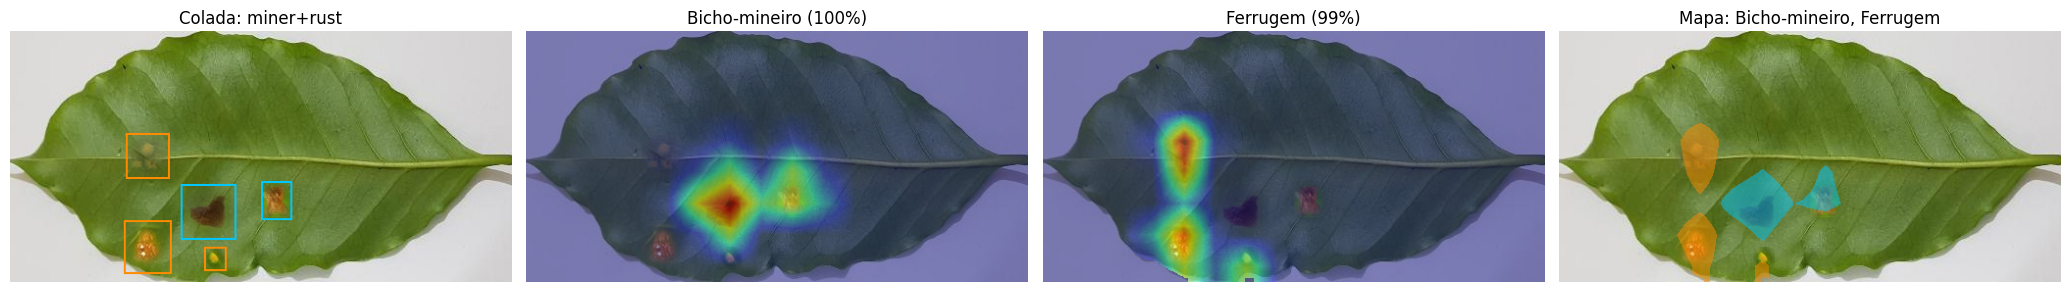

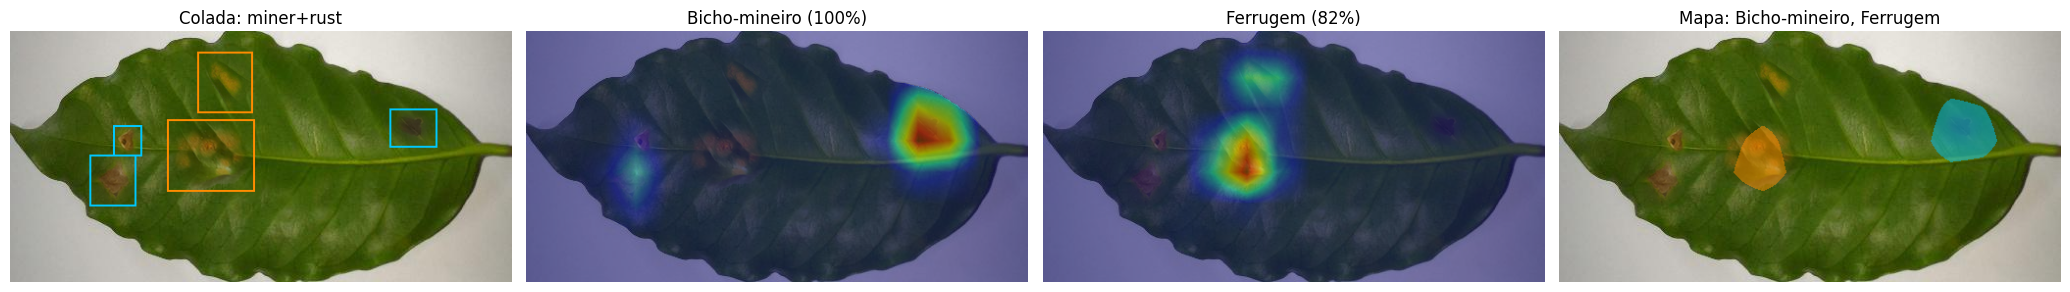

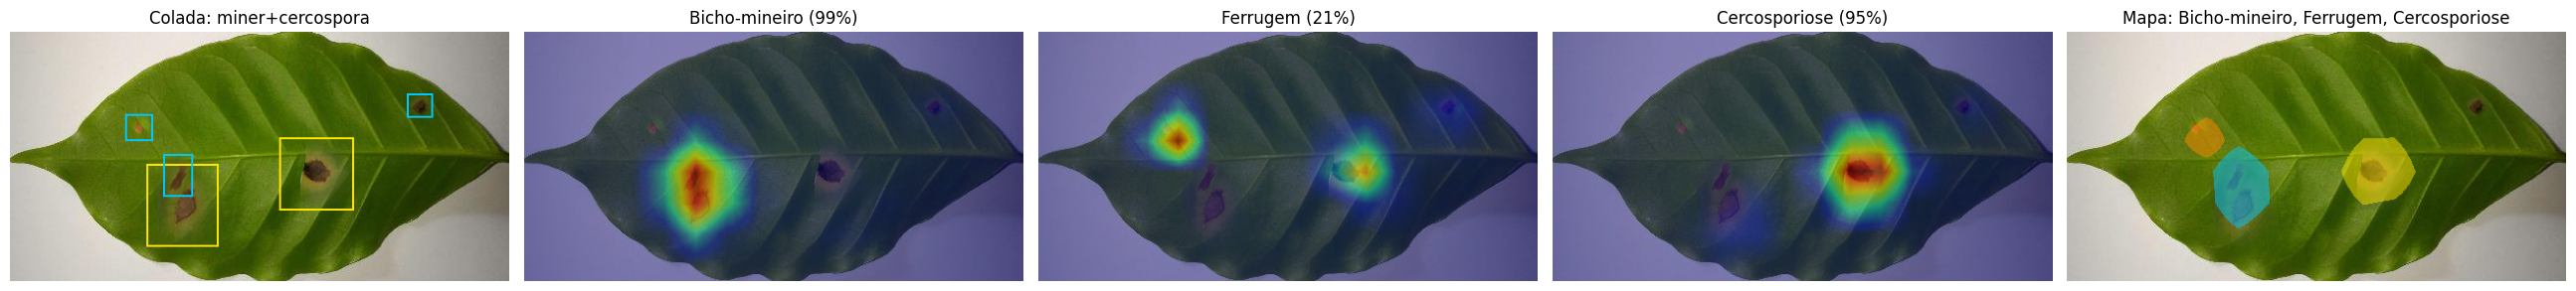

In [17]:
# Folha saudável de teste com lesões coladas de duas doenças (posição exata conhecida)
rng = random.Random(11)
healthy_test = [i for i in split["test"] if leaves[i]["labels"].sum() == 0]
test_bank = mu.Lesion_Bank(crops, split["test"])   # lesões de folhas de teste: o modelo nunca as viu
for lid in rng.sample(healthy_test, 3):
    img = Image.open(leaves[lid]["path"]).convert("RGB").resize((mu.IMG_W, mu.IMG_H))
    lab, all_boxes = leaves[lid]["labels"], []
    for d in rng.sample(mu.DISEASES, 2):
        img, lab, b = mu.Paste_Lesions(img, lab, test_bank, rng, disease=d, n_range=(2, 3)); all_boxes += b
    show_leaf(img=img, gt_boxes=all_boxes, title="Colada: " + mu.Combo(lab))

## Teste cruzado: fotos de café do próprio projeto
As fotos do `EVAL_PATH` (Phoma, ferrugem e saudáveis, folha inteira em fundo claro) vêm de **outra fonte** (outro celular, outra lavoura, outra época). Elas têm uma doença por foto. O teste mede:
- se o modelo **acha a doença certa**;
- se ele **inventa doenças** que não estão lá.

As fotos passam pelo mesmo preparo: recorte da folha, folha deitada e redimensionamento para 512×256.

> **Recorte da folha:** este laboratório usa `mu.Leaf_BBox_Background`, com limiar de saturação **fixo** e filtro de cor. O `Leaf_BBox` do laboratório principal usa limiar automático, que sobe demais quando metade da folha é muito saturada; com isso, corta a metade verde-escura em 8,7% das fotos de teste.

In [18]:
if PROJECT_TEST and os.path.isdir(PROJECT_TEST):
    import torchvision.datasets as datasets
    proj = datasets.ImageFolder(PROJECT_TEST)
    target = {"Phoma": "phoma", "Rust": "rust", "Healthy": None}
    stats = collections.defaultdict(lambda: {"n": 0, "certa": 0, "extras": 0, "saudavel_ok": 0})
    net.eval()
    for path, y in proj.samples:
        cls = proj.classes[y]
        img = mu.To_Leaf_Frame(Image.open(path))
        with torch.no_grad():
            p = torch.sigmoid(net(tf(img).unsqueeze(0).to(DEVICE)))[0].cpu().numpy()
        found = {mu.DISEASES[k] for k in range(4) if p[k] >= THR[k]}
        s = stats[cls]; s["n"] += 1
        if target[cls] is None:
            s["saudavel_ok"] += not found
        else:
            s["certa"] += target[cls] in found
            s["extras"] += bool(found - {target[cls]})
    for cls, s in stats.items():
        if target[cls] is None:
            print(f"{cls:8s} n={s['n']:3d} | sem nenhuma doença detectada: {s['saudavel_ok'] / s['n'] * 100:.1f}%")
        else:
            print(f"{cls:8s} n={s['n']:3d} | doença certa encontrada: {s['certa'] / s['n'] * 100:.1f}% | com alguma doença a mais: {s['extras'] / s['n'] * 100:.1f}%")
else:
    print("EVAL_PATH não encontrado: teste cruzado pulado")

Healthy  n=105 | sem nenhuma doença detectada: 84.8%
Phoma    n=105 | doença certa encontrada: 1.9% | com alguma doença a mais: 99.0%
Rust     n=105 | doença certa encontrada: 97.1% | com alguma doença a mais: 26.7%


## Custo do modelo

In [19]:
params = sum(p.numel() for p in net.parameters())
x = torch.randn(1, 3, mu.IMG_H, mu.IMG_W)
lat = {}
for dev in (["cuda"] if DEVICE.type == "cuda" else []) + ["cpu"]:
    m = mu.Build_Multi_Model(pretrained=False).to(dev).eval(); m.load_state_dict(net.state_dict()); xx = x.to(dev)
    with torch.no_grad():
        for _ in range(5): m(xx)
        if dev == "cuda": torch.cuda.synchronize()
        t = time.perf_counter()
        for _ in range(30): m(xx)
        if dev == "cuda": torch.cuda.synchronize()
    lat[dev] = (time.perf_counter() - t) / 30 * 1000
print(f"Parâmetros: {params / 1e6:.2f} M | arquivo ~{params * 4 / 2**20:.0f} MB | " + " | ".join(f"{d}: {v:.1f} ms/foto" for d, v in lat.items()))
print("Referência: ConvNeXt-Tiny (modelo de uma doença) = 27,8 M parâmetros, 106 MB")

Parâmetros: 4.21 M | arquivo ~16 MB | cuda: 9.3 ms/foto | cpu: 37.0 ms/foto
Referência: ConvNeXt-Tiny (modelo de uma doença) = 27,8 M parâmetros, 106 MB


## Salvando o modelo
Salvo em um arquivo **novo**. Se `MODEL_PATH` já existir, o nome recebe data e hora; nenhum modelo existente é sobrescrito.

In [20]:
MODEL_PATH.parent.mkdir(parents=True, exist_ok=True)
assert not MODEL_PATH.exists()
torch.save({
    "model_state_dict": net.state_dict(),
    "class_names": mu.DISEASES,
    "num_classes": len(mu.DISEASES),
    "task": "multi-label",
    "thresholds": THR.tolist(),
    "model_info": {
        "version": "multi-1.0",
        "architecture": "mobilenet_v3_large",
        "input_size": [mu.IMG_H, mu.IMG_W],
        "preprocessing": "folha deitada ocupando a imagem, Resize(256x512), Normalize(ImageNet)",
        "training_data": "BRACOL (Esgario et al., 2020)" + (" + copy-paste de lesões" if best_name.startswith("B") else ""),
        "training_date": dt.datetime.now().strftime("%d-%m-%Y %H:%M:%S"),
        "test_mAP": float(row["mAP"]),
        "test_exact_match": float(row["acerto exato"]),
    },
}, MODEL_PATH)
print("Modelo salvo em", MODEL_PATH)

Modelo salvo em /home/kaua-matheus/Documents/Agroscope_IA/Steps/Models/Saved/Expert/Coffee/coffee_multi.pth


## Conclusões (execução de 06/11/2026)

**1. Identificar várias doenças na mesma folha: funciona, com ressalvas.**

| | Resultado no teste (435 folhas) |
|---|---|
| Qualidade geral (mAP / AUC) | 92,9% / 97,0% |
| Acerto exato (todas as doenças da folha, sem nenhuma a mais) | 77,9% |
| Folhas saudáveis sem nenhuma doença apontada | 98,5% |
| Folhas com 2+ doenças em que **todas** foram encontradas | 68,1% (72,5% com limiares × 0,6) |

- Ferrugem, Phoma e bicho-mineiro têm AP de 0,96 a 0,99.
- A **cercosporiose é o gargalo** (AP 0,77–0,82). As lesões são pequenas (~20 px na resolução 512×256 do BRACOL) e aparecem quase sempre junto com a ferrugem.
- O "encontrar todas" **oscila ~10 pontos entre execuções** (só 91 folhas com 2+ doenças no teste). Trate-o como uma faixa (58–72%), não como número exato.

**2. Onde está cada doença: o mapa de calor separa as doenças.**
- **Com as caixas reais do especialista**, o ponto mais quente cai numa lesão daquela doença em **54,6%** dos casos, contra 8,2% no chute (6,7× melhor):
  - bicho-mineiro e Phoma: 70–80%;
  - ferrugem: 27%, mas os mapas acendem em manchas de ferrugem que as caixas não marcam.
- **Nas folhas com 2 doenças**, o mapa de cada doença apontou para lesões **dela** em 50% e para lesões da **outra** em 0%.
- O teste com lesões coladas depende de o modelo ter treinado com colagem: o modelo B chega a 90–99% por doença, mas o modelo escolhido (A) não.

**3. Copy-paste de lesões.**
- **O que melhora (3 sementes):** a qualidade geral (mAP 92,1 ± 1,1 → 93,6 ± 0,1) e a cercosporiose (AP 0,76 → 0,80), com um modelo bem mais estável.
- **O que não melhora de forma confiável:** o "encontrar todas" nas folhas com 2+ doenças.
- **Qual modelo foi salvo:** a escolha pela validação, com o critério mAP + encontrar todas, ficou com o modelo **sem** colagem nesta execução.

**4. Modelo leve.** MobileNetV3, 4,2 M parâmetros e 16 MB: ~37 ms por foto em CPU e ~9 ms em GPU. É 7× menor que o ConvNeXt usado nos modelos de uma doença.

**5. Teste cruzado com as fotos do projeto.**
- **Ferrugem:** reconhecida em 97% das fotos (com uma doença a mais em 27%).
- **Saudáveis:** 85% sem nenhuma doença apontada.
- **Phoma:** só 1,9% reconhecida. As fotos de "Phoma" do projeto têm **manchas circulares claras com borda escura**, enquanto a "Phoma" do BRACOL são **manchas grandes, escuras e irregulares na borda da folha**. As duas bases provavelmente chamam de "Phoma" sintomas diferentes, e **um agrônomo precisa conferir os rótulos** antes de juntar as bases.

**6. Achado para o laboratório principal.** O `Leaf_BBox` (`Steps/utils/leaf.py`, também usado na API) **corta a metade verde-escura da folha em 8,7% das fotos de teste do café** (15% nas de Phoma). Causa: o limiar automático de saturação. `mu.Leaf_BBox_Background` (limiar fixo + filtro de cor) resolve, mas trocar no modelo principal exige retreiná-lo.

**Próximos passos**
- **Cercosporiose:** treinar com imagens em resolução maior; as fotos originais do BRACOL têm 2048×1024, mas o repositório só traz a versão 512×256.
- **Sensibilidade:** escolher o fator de limiar conforme o uso; para triagem no campo, vale priorizar encontrar todas as doenças.
- **Fotos de campo com mais de uma doença:** juntar e rotular algumas para teste real.
- **Phoma:** confirmar com um agrônomo o rótulo das duas bases.